# 01 · Datos, reglas y población
**Proyecto:** variabilidad de entrada al Skinpass · Ternium Pesquería, producción 2025

**Qué hace este notebook**
1. Carga los 24 archivos del Molino Caliente 4 (MC4) y los 12 del Skinpass (SKP).
2. Audita cobertura y consistencia.
3. Explica qué contiene cada tabla: grupos de columnas, columnas sin información y el bloque de defectos.
4. Explora el MC4: qué se lamina, si sale lo que se pidió y cómo se califica.
5. Explora el Skinpass: cómo trabaja, preset contra real y cómo se califica.
6. Aplica las reglas de limpieza fijadas antes de ver resultados.
7. Define producto y la subpoblación con destino al Skinpass.
8. Liga cada rollo del MC4 con su paso por el Skinpass y revisa qué cambia entre las dos líneas.

Los demás notebooks parten de las mismas funciones (`src/ternium.py`), así que todos usan la misma población.

## 0. Configuración
Importa `src/ternium.py`, donde viven la carga de datos y las reglas de limpieza. Basta con tener el repositorio clonado: los Excel ya vienen en `data/`.

In [1]:
# Solo en Colab: descarga el repo (datos incluidos) e instala dependencias. En local no hace nada.
import os, sys, subprocess
if 'google.colab' in sys.modules:
    REPO = '/content/Entregable_Reto'
    if not os.path.exists(REPO):
        subprocess.run(['git', 'clone', '-q', 'https://github.com/DiegoLarrieta/Entregable_Reto.git', REPO], check=True)
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', f'{REPO}/requirements.txt'], check=True)
    os.chdir(f'{REPO}/notebooks')

In [2]:
# Configuración: busca la carpeta del repo para poder importar src/ternium.py.
import sys
from pathlib import Path
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'ternium.py').exists())
sys.path.append(str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.ternium import *

estilo()
pd.set_option('display.max_columns', 20)

## 1. Carga
Los Excel se leen tal como los entregó Ternium, sin ediciones manuales. Cada fila del MC4 es un rollo; cada fila del Skinpass es una pieza (un rollo puede salir del Skinpass dividido en 2 o 3).

In [3]:
mc4 = cargar_mc4()
skp = cargar_skp()

print(f'MC4: {mc4.shape[0]:,} rollos · {mc4.shape[1] - 1} columnas · {mc4.Origen_Archivo.nunique()} archivos')
print(f'SKP: {skp.shape[0]:,} piezas · {skp.shape[1] - 1} columnas · {skp.Origen_Archivo.nunique()} archivos')

MC4: 149,734 rollos · 280 columnas · 24 archivos
SKP: 58,786 piezas · 208 columnas · 12 archivos


/Users/diego/Entregable_Reto/src/ternium.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat(
/Users/diego/Entregable_Reto/src/ternium.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat(


## 2. Auditoría
Revisamos tres cosas antes de analizar: que no falten periodos, que no haya rollos duplicados y que las fechas caigan en 2025.

In [4]:
# Rollos por mes real de laminación (no por el nombre del archivo).
por_mes = pd.DataFrame({
    'MC4': mc4['Fecha Inicio'].dt.to_period('M').value_counts().sort_index(),
    'Skinpass': skp['Fecha Inicio'].dt.to_period('M').value_counts().sort_index(),
}).fillna(0).astype(int)
print(por_mes.to_string())
por_mes = por_mes[por_mes.index.year == 2025]   # las pocas filas de dic-2024 son turnos que cruzan la medianoche

print('\nRollos MC4 duplicados (Material Salida):', mc4['Material Salida'].duplicated().sum())
print('Piezas SKP duplicadas (Material Salida):', skp['Material Salida'].duplicated().sum())

                MC4  Skinpass
Fecha Inicio                 
2024-12         110        39
2025-01       14238      5429
2025-02       11150      4574
2025-03       13045      5298
2025-04       11951      4992
2025-05       11827      5034
2025-06       12041      4868
2025-07       13148      4836
2025-08       12757      5369
2025-09       10731      3579
2025-10       11465      5038
2025-11       14170      4919
2025-12       13101      4811

Rollos MC4 duplicados (Material Salida): 0
Piezas SKP duplicadas (Material Salida): 0


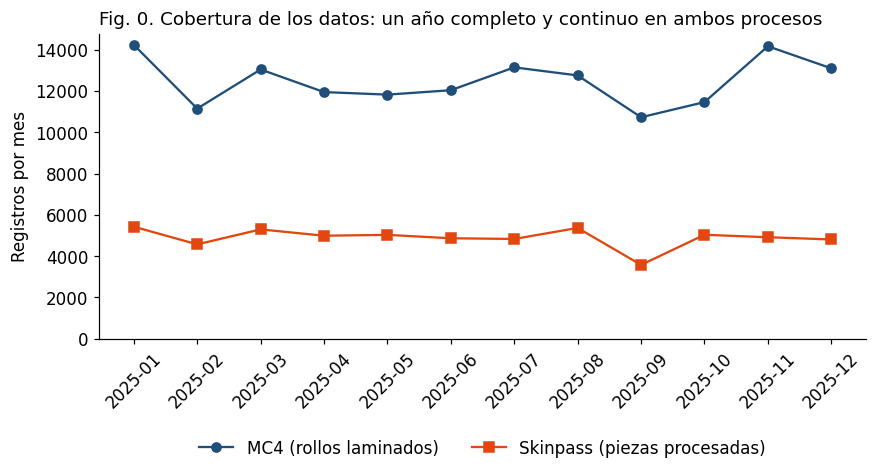

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.6))
x = por_mes.index.astype(str)
ax.plot(x, por_mes.MC4, 'o-', color=COLORES['azul'], label='MC4 (rollos laminados)')
ax.plot(x, por_mes.Skinpass, 's-', color=COLORES['naranja'], label='Skinpass (piezas procesadas)')
ax.set_ylabel('Registros por mes')
ax.set_ylim(0)
ax.tick_params(axis='x', rotation=45)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.28), ncol=2)
ax.set_title('Fig. 0. Cobertura de los datos: un año completo y continuo en ambos procesos')
guardar(fig, 'fig0_cobertura')
plt.show()

**Qué vemos.** Los dos procesos cubren los 12 meses de 2025 sin huecos. El MC4 lamina del orden de 12 mil rollos al mes y el Skinpass procesa unas 5 mil piezas; la diferencia es esperable, porque solo una parte de los rollos va al Skinpass. Algunas filas del Skinpass caen en los últimos minutos de 2024: son turnos que empezaron antes de la medianoche. No hay rollos duplicados en MC4.

## 3. Qué contiene cada tabla
Antes de analizar hay que saber qué es cada columna. El MC4 tiene 280 columnas y el Skinpass 208 (sin contar `Origen_Archivo`), pero casi la mitad son el **bloque de defectos**: los mismos campos repetidos 5 veces, `Defecto (1)` a `Defecto (5)`.

Agrupamos las columnas por lo que significan para el análisis. La función `perfil_columnas` de `src/ternium.py` da, por columna, su grupo, tipo, % de valores llenos, valores distintos y un ejemplo.

In [6]:
perf_mc4 = perfil_columnas(mc4.drop(columns='Origen_Archivo'))
perf_skp = perfil_columnas(skp.drop(columns='Origen_Archivo'))

por_grupo = pd.concat({
    'MC4': perf_mc4.groupby('grupo').agg(columnas=('tipo', 'size'), lleno_promedio=('% lleno', 'mean')),
    'Skinpass': perf_skp.groupby('grupo').agg(columnas=('tipo', 'size'), lleno_promedio=('% lleno', 'mean')),
}, axis=1).fillna(0).round(0).astype(int)
por_grupo.sort_values(('MC4', 'columnas'), ascending=False)

MC4                Skinpass  \
                                             columnas lleno_promedio columnas   
grupo                                                                           
Defectos (5 bloques)                              125             26      120   
Especificación del pedido                          36             81       21   
Actuadores y operación                             29             91       20   
Mediciones del rollo o pieza                       24             66       14   
Identificación y trazabilidad                      14            100       12   
Entrada (planchón al MC4, rollo al Skinpass)       13            100        4   
Temperaturas medidas                               13             92        0   
Calidad y dictamen                                 12             88       15   
Tiempo                                             11             91        2   
Otros                                               3              0        0   

                                                             
                                             lleno_promedio  
grupo                                                        
Defectos (5 bloques)                                      3  
Especificación del pedido                                68  
Actuadores y operación                                  100  
Mediciones del rollo o pieza                             65  
Identificación y trazabilidad                            94  
Entrada (planchón al MC4, rollo al Skinpass)            100  
Temperaturas medidas                                      0  
Calidad y dictamen                                       66  
Tiempo                                                  100  
Otros                                                     0

**Cómo leer los grupos**

| Grupo | Qué es | Uso en el análisis |
|---|---|---|
| Identificación y trazabilidad | Llaves del rollo o pieza, orden, programa, colada, cliente | Ligar tablas y agrupar; no explican nada físico |
| Tiempo | Fechas de inicio y fin, estancias, respuestas de loopers | Orden temporal y tiempos de proceso |
| Especificación del pedido | Lo que se **pidió**: objetivos, mínimos y máximos, norma, grado, ruta | Define el producto y la tolerancia |
| Entrada | En el MC4, el planchón y el horno; en el Skinpass, el rollo que llega | Condición de partida |
| Temperaturas medidas | Temperaturas reales en los castillos F1 a F7, acabado y enrollado | Cómo se laminó |
| Actuadores y operación | Lo que hizo la línea: canteo, loopers, presets y valores reales de fuerza, tensión y bending | Palancas que se pueden mover |
| Mediciones del rollo o pieza | Lo que **salió**: espesor, ancho, peso, corona, acuñamiento, elongación | Resultados físicos |
| Calidad y dictamen | El juicio: dictamen, resolución, observaciones | Se decide **después** de medir: nunca usarlo para explicar |
| Defectos (5 bloques) | Hasta 5 defectos por rollo o pieza, con su origen, causa y calificación | Resultado de calidad, una fila por defecto |

La lista completa de columnas por grupo:

In [7]:
import textwrap

def listar(perf, titulo):
    print(f'===== {titulo}')
    for grupo, g in perf[perf['grupo'] != 'Defectos (5 bloques)'].groupby('grupo'):
        print(f'\n{grupo} ({len(g)})')
        print(textwrap.fill(', '.join(g.index.str.strip()), width=110, initial_indent='  ', subsequent_indent='  '))

listar(perf_mc4, 'MC4')
print()
listar(perf_skp, 'Skinpass')

===== MC4

Actuadores y operación (29)
  Enrollador, Canteo R1, Canteo R2, Canteo SSP, SSP Utilizado, Uso Modelo Calentamiento, Kelk Activo, Long.
  Barra Transferencia, % Uso Modelo, % Uso Cubierta Térmica, Offsets de Guías - Enrollador, Cambio Rodillo
  Trabajo, Uso Aceite Rolado, topSpyOnH, botSpyOnH, topSpyOnM, botSpyOnM, topSpyOnT, botSpyOnT, Offset de
  Ancho Manual, Tensión de Looper 1 [Mpa], Tensión de Looper 2 [Mpa], Tensión de Looper 3 [Mpa], Tensión de
  Looper 4 [Mpa], Tensión de Looper 5 [Mpa], Tensión de Looper 6 [Mpa], Nro. Flejes Radial, Nro. Flejes
  Circunf., Taper Plc ID

Calidad y dictamen (12)
  Muestrear Obj., Dictamen, Resolución, Calidad Sugerida, Mal Enrollado, Afectado Superposición, Es Reproceso,
  Envío a Inspección, Motivo Superposición, Spring Back Salida, Muestrear, Muestreado

Entrada (planchón al MC4, rollo al Skinpass) (13)
  Horno, Ancho Entrada, Espesor Entrada, Peso Asignado Entrada, Origen Peso Entrada, Ancho Entrada Real,
  Espesor Entrada Real, L

### 3.1 Columnas que no aportan información
Una columna vacía (menos de 1% de valores) o constante (un solo valor) no sirve para el análisis. Conviene saber cuáles son para no perder tiempo con ellas.

In [8]:
def sin_informacion(perf):
    p = perf[perf['grupo'] != 'Defectos (5 bloques)']
    vacias = p.index[p['% lleno'] < 1].str.strip().tolist()
    constantes = p.index[(p['% lleno'] >= 1) & (p['distintos'] == 1)].str.strip().tolist()
    return vacias, constantes

for nombre, perf in [('MC4', perf_mc4), ('Skinpass', perf_skp)]:
    vacias, constantes = sin_informacion(perf)
    print(f'{nombre}: {len(vacias)} vacías y {len(constantes)} constantes')
    print(textwrap.fill('Vacías: ' + ', '.join(vacias), 110, subsequent_indent='  '))
    print(textwrap.fill('Constantes: ' + ', '.join(constantes), 110, subsequent_indent='  '))
    print()

MC4: 18 vacías y 13 constantes
Vacías: Proceso Siguiente, Espesor Punta, Espesor Cola, Temp. Acabador Inf., Criticidad Temperatura, Uso
  Modelo Calentamiento, Línea Adelantada SKP, % Elongación Mínimo, % Elongación Máximo, Espesor Mínimo SKP,
  Espesor Máximo SKP, Tipo Corte Punta, Longitud Corte Punta, Peso Corte Punta, Tipo Corte Cola, Longitud
  Corte Cola, Peso Corte Cola, Kelk Activo
Constantes: Estado, Forma Final MC, Código Forma, Muestrear Obj., Diam Interior, Mal Enrollado, Es Reproceso,
  Uso Aceite Rolado, Taper Plc ID, Taper Teórico, Taper Teo. Ancho Punta, Taper Teo. Ancho Cola, Muestreado

Skinpass: 10 vacías y 5 constantes
Vacías: Forma Final, Espesor Punta, Espesor Cola, Calibre, Solución, Código Acabado, Código Forma,
  Reflectividad, Acabado Superficial, Cara Garantizada
Constantes: Estado, Diam Interior, Sociedad, Empaque Cumple, Cara Inspeccionar



**Qué vemos.** El MC4 tiene 18 columnas vacías y 13 constantes; el Skinpass, 10 y 5. Destacan las que **parecerían útiles pero vienen vacías**: en el MC4, `Espesor Punta` y `Espesor Cola`, los cortes de punta y cola, y `% Elongación Mínimo/Máximo` y `Espesor Mínimo/Máximo SKP` (la especificación del Skinpass no viaja en el MC4); en el Skinpass, `Reflectividad` y `Espesor Punta/Cola`. No hay medición de punta ni de cola en ninguna de las dos tablas.

### 3.2 El bloque de defectos
Cada rollo o pieza tiene hasta 5 defectos. Cada defecto trae los mismos campos; la diferencia entre tablas es que el MC4 califica cada defecto con `Dictamen (k)` y el Skinpass con `Calidad (k)`.

In [9]:
campos = lambda df: [c[:-4] for c in df.columns if c.endswith('(1)')]
cm, cs = campos(mc4), campos(skp)
print(f'MC4: {len(cm)} campos por defecto · Skinpass: {len(cs)} campos por defecto')
print(textwrap.fill('Campos: ' + ', '.join(cm), 110, subsequent_indent='  '))
print('Solo en MC4:', sorted(set(cm) - set(cs)), '· Solo en Skinpass:', sorted(set(cs) - set(cm)))

n_def = pd.DataFrame({
    'MC4 (rollos)': mc4[[f'Defecto ({k})' for k in range(1, 6)]].notna().sum(axis=1).value_counts(normalize=True),
    'Skinpass (piezas)': skp[[f'Defecto ({k})' for k in range(1, 6)]].notna().sum(axis=1).value_counts(normalize=True),
}).sort_index().mul(100).round(1)
n_def.index.name = 'defectos registrados'
n_def

MC4: 25 campos por defecto · Skinpass: 24 campos por defecto
Campos: Codigo defecto, Defecto, Ubicacion, Es Contencion, Es Prevencion, Es Mejora, Intensidad, Cara, Lado,
  Linea Origen, Dictamen, Resolución, Calidad Sugerida, Siguiente Accion, Siguiente Proceso, Mts Ini, Mts Fin,
  Frecuencia, Causa, Accion Preventiva, Accion Correctiva, Observaciones, Fecha Registro, Registro Automatico,
  Código Equipo
Solo en MC4: ['Dictamen', 'Resolución'] · Solo en Skinpass: ['Calidad']


,MC4 (rollos),Skinpass (piezas)
defectos registrados,,
0,11.5,78.2
1,28.0,19.4
2,29.2,2.1
3,18.6,0.3
4,8.6,0.0
5,4.1,0.0


**Qué vemos.** En el MC4 casi todos los rollos tienen al menos un defecto (solo 11.5% sale sin ninguno) y es común que tengan 2 o 3. En el Skinpass es al revés: más de 3 de cada 4 piezas salen sin defectos. Un "defecto" en el MC4 no equivale a un rollo malo: muchos son registros automáticos contra una tolerancia (se estudia en `02_calidad`).

## 4. Exploración del MC4
### 4.1 Qué se lamina
Distribución de lo que se pide al MC4: dimensiones, peso, largo y temperaturas objetivo.

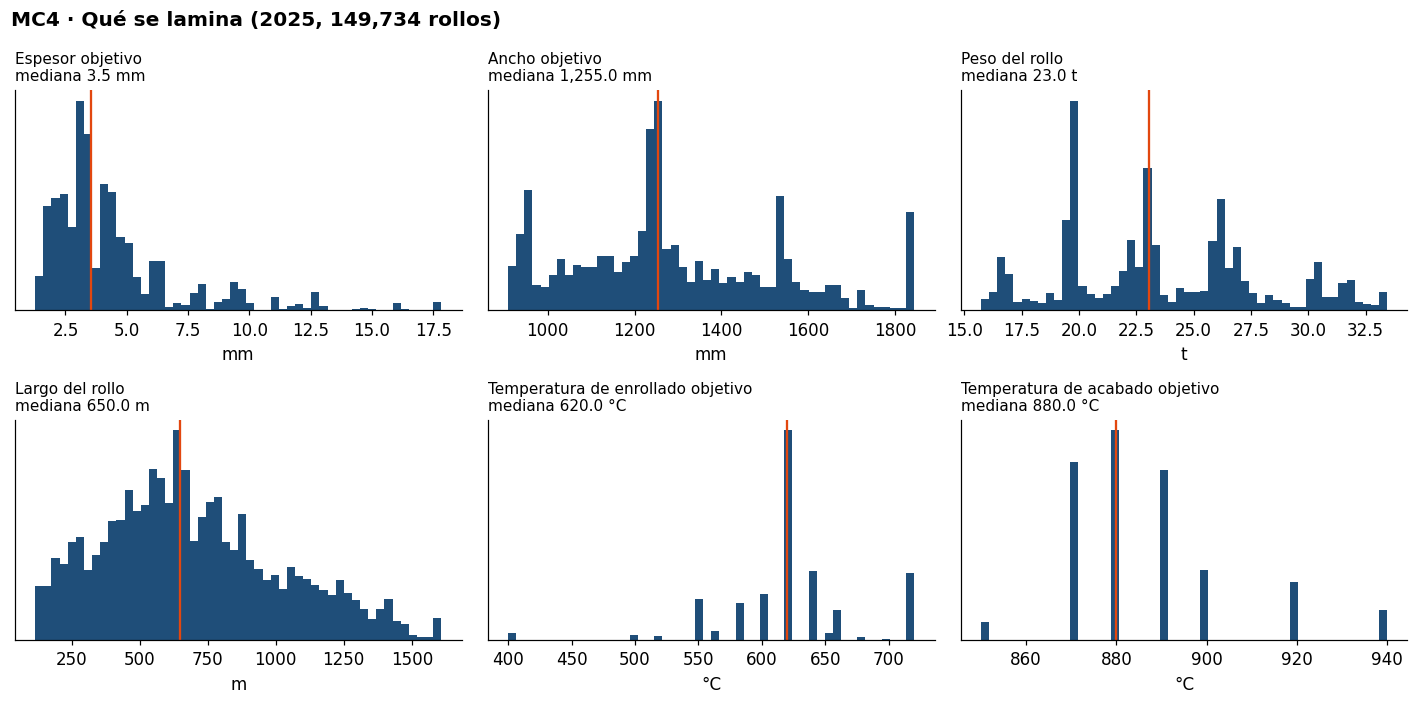

Normas: 49 · Grados: 513 · Clientes: 442
Los 10 clientes principales suman 39% de los rollos


,rollos
Norma,
TER,80282
SAE J403,15548
GMW3032M-ST-S,8396
ASTM A 1011,8171
ASTM A 36,5294
SAE J2340,5246
ASTM A 572,4627
PSC,4565


In [10]:
vars_mc4 = {
    'Espesor Objetivo': ('Espesor objetivo', 'mm', 1),
    'Ancho Objetivo': ('Ancho objetivo', 'mm', 1),
    'Peso': ('Peso del rollo', 't', 1000),
    'Largo': ('Largo del rollo', 'm', 1),
    'Temp Enrollado Obj': ('Temperatura de enrollado objetivo', '°C', 1),
    'Temp Acabado Obj': ('Temperatura de acabado objetivo', '°C', 1),
}
fig, axs = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, (col, (nombre, unidad, div)) in zip(axs.flat, vars_mc4.items()):
    v = mc4[col].dropna() / div
    ax.hist(v.clip(v.quantile(.005), v.quantile(.995)), bins=50, color=COLORES['azul'])
    ax.axvline(v.median(), color=COLORES['naranja'], lw=1.5)
    ax.set_title(f'{nombre}\nmediana {v.median():,.1f} {unidad}', fontsize=10)
    ax.set_xlabel(unidad); ax.set_yticks([])
fig.suptitle('MC4 · Qué se lamina (2025, 149,734 rollos)', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
guardar(fig, 'eda_mc4_producto')
plt.show()

print(f"Normas: {mc4['Norma'].nunique()} · Grados: {mc4['Grado'].nunique()} · Clientes: {mc4['Cliente'].nunique()}")
print(f"Los 10 clientes principales suman {mc4['Cliente'].value_counts(normalize=True).head(10).sum():.0%} de los rollos")
mc4['Norma'].value_counts().head(8).to_frame('rollos')

**Qué vemos.** El MC4 lamina sobre todo lámina delgada: la mediana de espesor objetivo es 3.5 mm y el 90% está entre 1.9 y 10 mm. Los anchos van de unos 950 a 1,750 mm y un rollo típico pesa unas 23 t. Las temperaturas objetivo no son continuas: son unas cuantas **consignas** fijas (la más común, 620 °C de enrollado y 880 °C de acabado). La norma interna `TER` concentra más de la mitad de los rollos. La mezcla es muy diversa (49 normas, más de 500 grados, 442 clientes), y por eso el análisis compara dentro de un mismo producto y no entre productos.

### 4.2 ¿Sale lo que se pidió?
Comparamos cada medición con su objetivo y con su tolerancia (mínimo y máximo de la misma fila).

In [11]:
def cumplimiento(df, real, minimo, maximo, objetivo=None, escala=1):
    ok = df[[real, minimo, maximo]].notna().all(axis=1)
    d = df.loc[ok]
    fila = {'con dato %': 100 * ok.mean(),
            'dentro de tolerancia %': 100 * d[real].between(d[minimo], d[maximo]).mean()}
    if objetivo:
        dev = (d[real] - d[objetivo]) * escala
        fila.update({'desviación mediana': dev.median(), 'p5': dev.quantile(.05), 'p95': dev.quantile(.95)})
    return fila

cump_mc4 = pd.DataFrame({
    'Espesor (µm)': cumplimiento(mc4, 'Espesor', 'Espesor Mínimo', 'Espesor Máximo', 'Espesor Objetivo', 1000),
    'Ancho (mm)': cumplimiento(mc4, 'Ancho', 'Ancho Mínimo', 'Ancho Máximo', 'Ancho Objetivo'),
    'Peso (kg)': cumplimiento(mc4, 'Peso', 'Peso Mínimo', 'Peso Máximo'),
    'Temp. enrollado (°C)': cumplimiento(mc4, 'Temp Enrollado Real', 'Temp Enrollado Min', 'Temp Enrollado Max', 'Temp Enrollado Obj'),
    'Temp. acabado (°C)': cumplimiento(mc4, 'Temp Acabado Real', 'Temp Acabado Min', 'Temp Acabado Max', 'Temp Acabado Obj'),
}).T.round(1)
cump_mc4

,con dato %,dentro de tolerancia %,desviación mediana,p5,p95
Espesor (µm),100.0,99.7,2.0,-1.0,6.0
Ancho (mm),100.0,99.5,1.5,-2.9,8.8
Peso (kg),100.0,98.3,NaN,NaN,NaN
Temp. enrollado (°C),96.0,98.1,-4.6,-12.6,1.9
Temp. acabado (°C),96.0,92.6,-4.8,-23.9,4.0


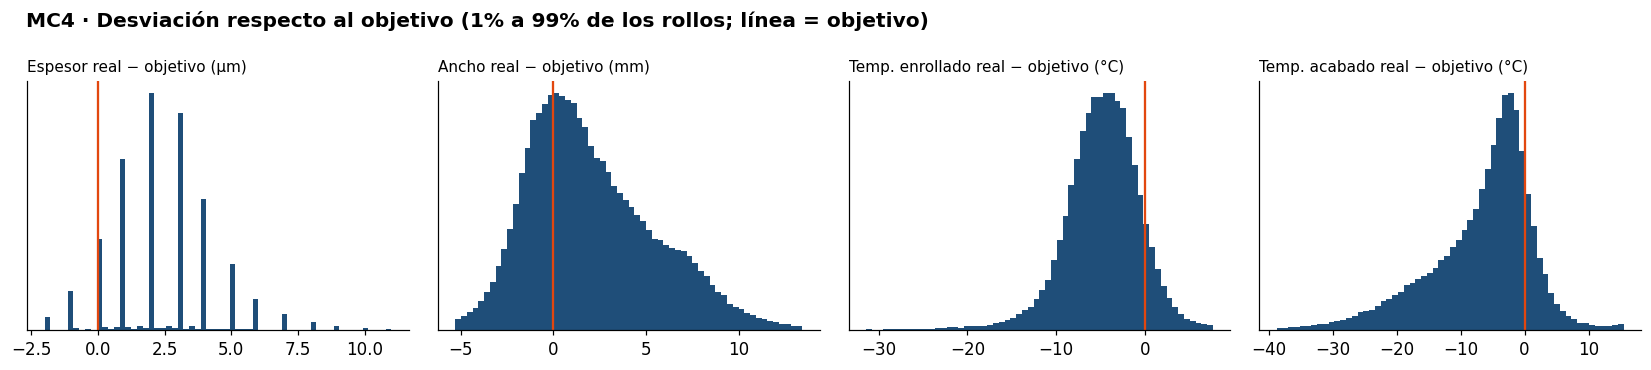

In [12]:
desv = {
    'Espesor real − objetivo (µm)': (mc4['Espesor'] - mc4['Espesor Objetivo']) * 1000,
    'Ancho real − objetivo (mm)': mc4['Ancho'] - mc4['Ancho Objetivo'],
    'Temp. enrollado real − objetivo (°C)': mc4['Temp Enrollado Real'] - mc4['Temp Enrollado Obj'],
    'Temp. acabado real − objetivo (°C)': mc4['Temp Acabado Real'] - mc4['Temp Acabado Obj'],
}
fig, axs = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, (nombre, v) in zip(axs, desv.items()):
    v = v.dropna()
    lo, hi = v.quantile([.01, .99])
    ax.hist(v[v.between(lo, hi)], bins=60, color=COLORES['azul'])
    ax.axvline(0, color=COLORES['naranja'], lw=1.5)
    ax.set_title(nombre, fontsize=10); ax.set_yticks([])
fig.suptitle('MC4 · Desviación respecto al objetivo (1% a 99% de los rollos; línea = objetivo)', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
guardar(fig, 'eda_mc4_desviaciones')
plt.show()

**Qué vemos.**
- **Espesor y ancho se cumplen casi siempre** con el valor resumen del rollo: 99.7% y 99.5% dentro de tolerancia. El espesor sale centrado (mediana +2 µm) y el ancho, un poco por encima del objetivo (mediana +1.5 mm): se lamina con un margen de ancho a propósito.
- **Las temperaturas son lo que más se desvía.** El enrollado queda en promedio unos 5 °C por debajo del objetivo, y el acabado es la variable con menor cumplimiento (92.6%).
- **Contradicción importante:** si el 99.7% del espesor está en tolerancia, ¿por qué `ESPESOR (+/-)` es el defecto más registrado del MC4? Porque el defecto se evalúa sobre el perfil a lo largo del rollo, y aquí solo tenemos un valor resumen por rollo. **El valor resumen no basta para reconstruir los defectos dimensionales.**

### 4.3 Cómo se califica un rollo

In [13]:
print('Dictamen del MC4:'); print(mc4['Dictamen'].value_counts(normalize=True).mul(100).round(1).to_string())
print()
pd.crosstab(mc4['Resolución'], mc4['Dictamen'], margins=True)

Dictamen del MC4:
Dictamen
RETENIDO    50.2
ACEPTADO    49.8



Dictamen,ACEPTADO,RETENIDO,All
Resolución,,,
CALIDAD DE PLANTA,0,70200,70200
CON OBSERVACIONES,57351,0,57351
CONSULTA A IP,0,3799,3799
POR PROGRAMACION,0,1183,1183
SOBRE ORDEN,17201,0,17201
All,74552,75182,149734


**Qué vemos.** La mitad de los rollos sale del MC4 como **RETENIDO**, pero eso no significa que se desechen: es una retención para revisión. `Resolución` no agrega información, porque cada valor corresponde a un solo dictamen: los retenidos son casi todos *calidad de planta* y los aceptados son *con observaciones* o *sobre orden*. En el notebook `investigacion` se ve que el 91% de los rollos retenidos en el MC4 que pasaron al Skinpass terminaron aceptados ahí. Por eso el `Dictamen` del MC4 es una mala variable de resultado.

### 4.4 Valores sospechosos
Valores que no se pueden usar tal como vienen.

In [14]:
dev_te = mc4['Temp Enrollado Real'] - mc4['Temp Enrollado Obj']
sospechosos = pd.Series({
    'Corona fuera de 0-300 µm': (~mc4['Corona Salida'].between(0, 300) & mc4['Corona Salida'].notna()).sum(),
    'Temp. enrollado a más de 100 °C del objetivo': (dev_te.abs() > 100).sum(),
    'Espesor a más de 1 mm del objetivo': ((mc4['Espesor'] - mc4['Espesor Objetivo']).abs() > 1).sum(),
    'Peso Báscula = 0 (no se pesó en báscula)': (mc4['Peso Báscula'] == 0).sum(),
    'Columnas topSpyOn* con valores > 1e80': int((mc4['botSpyOnH'] > 1e80).sum()),
}, name='rollos')
sospechosos.to_frame()

,rollos
Corona fuera de 0-300 µm,5145
Temp. enrollado a más de 100 °C del objetivo,740
Espesor a más de 1 mm del objetivo,349
Peso Báscula = 0 (no se pesó en báscula),140398
Columnas topSpyOn* con valores > 1e80,147390


**Qué vemos.**
- La **corona** tiene valores imposibles: se depuran con la regla de la sección 6.
- Unos cientos de rollos tienen la **temperatura** o el **espesor** muy lejos del objetivo. Son pocos, pero distorsionan promedios: conviene usar medianas o recortar extremos.
- `Peso Báscula` vale 0 en el 94% de los rollos: el peso confiable es `Peso`.
- Las columnas `topSpyOn*` y `botSpyOn*` tienen números como 1.0001e+91: son **códigos** de qué rociadores estaban encendidos (cada dígito es un rociador), no magnitudes. No se pueden usar como números.

## 5. Exploración del Skinpass
### 5.1 Cómo trabaja
El Skinpass opera en dos modos: controlando la **elongación** (modo SKP) o controlando la **fuerza** (modo RCO).

Elongación faltante  False  True 
Modo Molino                      
Elongación           53259      1
Fuerza                 291   5235

Piezas por rollo: {1: 40770, 2: 8352, 3: 428, 4: 7}
Piezas de un rollo dividido: 29.6%


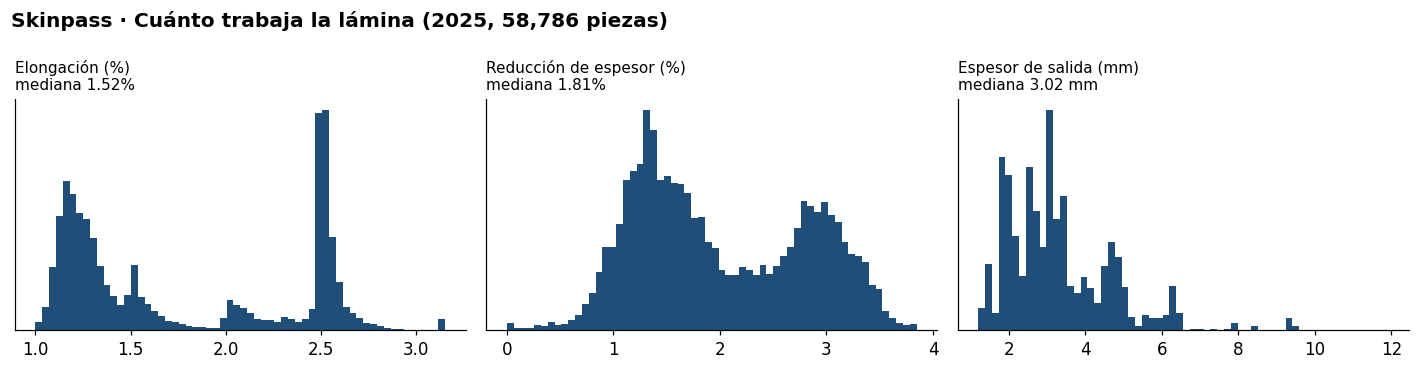

In [15]:
print(pd.crosstab(skp['Modo Molino'], skp['Elongación'].isna(), colnames=['Elongación faltante']).to_string())
reduccion = 100 * (skp['Espesor Entrada'] - skp['Espesor Salida']) / skp['Espesor Entrada']
print(f"\nPiezas por rollo: {skp.groupby('Material Entrada').size().value_counts().sort_index().to_dict()}")
print(f"Piezas de un rollo dividido: {(skp['Dividido'] == 'SI').mean():.1%}")

fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
e = skp['Elongación'].dropna()
axs[0].hist(e.clip(upper=e.quantile(.995)), bins=60, color=COLORES['azul'])
axs[0].set_title(f'Elongación (%)\nmediana {e.median():.2f}%', fontsize=10)
r = reduccion[reduccion.between(0, reduccion.quantile(.995))]
axs[1].hist(r, bins=60, color=COLORES['azul'])
axs[1].set_title(f'Reducción de espesor (%)\nmediana {r.median():.2f}%', fontsize=10)
es = skp['Espesor Salida']
axs[2].hist(es, bins=60, color=COLORES['azul'])
axs[2].set_title(f'Espesor de salida (mm)\nmediana {es.median():.2f} mm', fontsize=10)
for ax in axs: ax.set_yticks([])
fig.suptitle('Skinpass · Cuánto trabaja la lámina (2025, 58,786 piezas)', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
guardar(fig, 'eda_skp_proceso')
plt.show()

**Qué vemos.**
- El 91% de las piezas se procesa en modo **elongación** y el 9% en modo **fuerza** (RCO). En modo fuerza casi nunca se registra la elongación: **el 9% de elongación faltante no es al azar**, corresponde a ese modo.
- El Skinpass estira la lámina muy poco: elongación mediana de 1.5% (casi todo entre 1.1% y 2.6%), y el espesor baja alrededor de 1.8%. Es un paso de acabado, no de reducción.
- 3 de cada 10 piezas salen de un rollo **dividido** en 2 o más piezas: la unidad del Skinpass (pieza) no es la misma que la del MC4 (rollo).

### 5.2 Preset contra real
Antes de cada pieza el modelo fija un **preset** de fuerza, bending y tensiones; durante el proceso se registra el promedio **real**. Si el real se aleja del preset, la línea tuvo que corregir sobre la marcha.

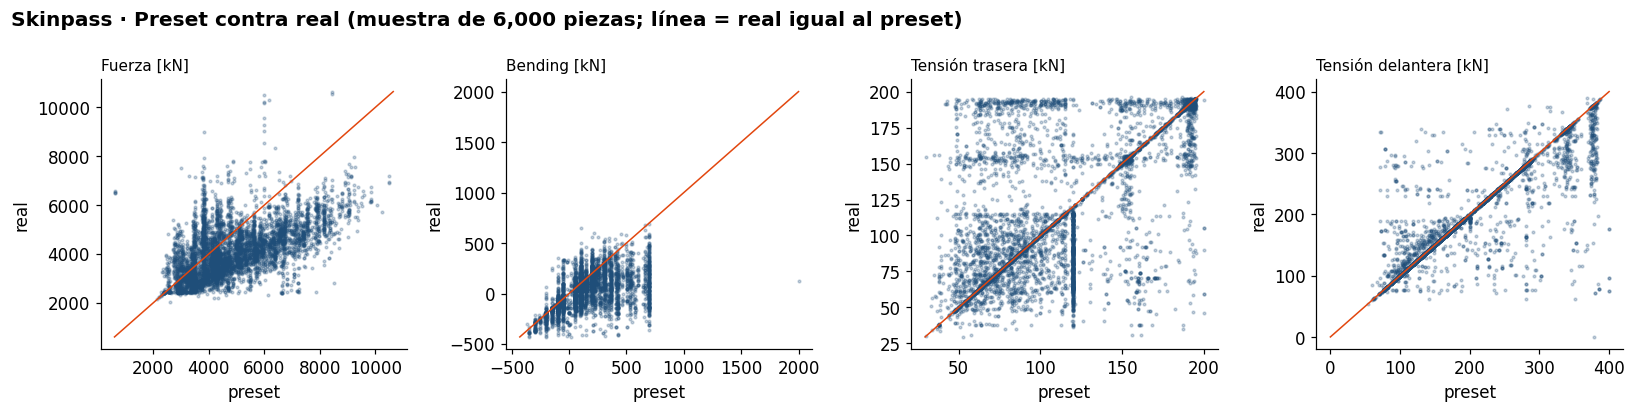

,preset = 0 %,mediana preset,mediana real,mediana real − preset,correlación
Fuerza [kN],7.73,4518.55,3973.4,-837.25,0.55
Bending [kN],11.80,100.00,53.0,-45.00,0.51
Tensión trasera [kN],0.00,106.70,103.9,0.00,0.64
Tensión delantera [kN],0.00,184.10,182.7,-0.20,0.89


In [16]:
pares = {
    'Fuerza [kN]': ('Preset Fuerza [kN]', 'Fuerza Real Prom.  [kN]'),
    'Bending [kN]': ('Preset Bending', 'Bending Prom. Real [kN]'),
    'Tensión trasera [kN]': ('Back Preset Tensión [kN]', 'Back Tensión Real Prom. [kN]'),
    'Tensión delantera [kN]': ('Front Preset Tensión [kN]', 'Front Tensión Real Prom. [kN]'),
}
filas = {}
fig, axs = plt.subplots(1, 4, figsize=(15, 3.8))
muestra = skp.sample(6000, random_state=0)
for ax, (nombre, (p, r)) in zip(axs, pares.items()):
    con_preset = skp[p] != 0
    d = skp.loc[con_preset, [p, r]].dropna()
    filas[nombre] = {'preset = 0 %': 100 * (~con_preset).mean(), 'mediana preset': d[p].median(),
                     'mediana real': d[r].median(), 'mediana real − preset': (d[r] - d[p]).median(),
                     'correlación': d[p].corr(d[r])}
    m = muestra[muestra[p] != 0]
    ax.scatter(m[p], m[r], s=3, alpha=.25, color=COLORES['azul'])
    lim = [min(m[p].min(), m[r].min()), max(m[p].max(), m[r].max())]
    ax.plot(lim, lim, color=COLORES['naranja'], lw=1)
    ax.set_title(nombre, fontsize=10); ax.set_xlabel('preset'); ax.set_ylabel('real')
fig.suptitle('Skinpass · Preset contra real (muestra de 6,000 piezas; línea = real igual al preset)', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
guardar(fig, 'eda_skp_preset_real')
plt.show()
pd.DataFrame(filas).T.round(2)

**Qué vemos.**
- La **tensión delantera** sigue al preset (correlación de 0.89). La **trasera** también en la mayoría de las piezas, pero hay grupos donde el real se va a topes cercanos a 150 y 190 kN.
- La **fuerza** y el **bending** son los que se corrigen: la fuerza real queda unos 840 kN por debajo del preset y el bending real, muy por debajo del suyo, con correlaciones de solo 0.5. Además, el 8% de las piezas no tiene preset de fuerza y el 12% no tiene preset de bending.
- Esta diferencia entre preset y real es justo lo que el Skinpass "tuvo que hacer" para corregir la lámina que llegó, y es el candidato natural a variable de respuesta para el análisis de la entrada al Skinpass.

### 5.3 ¿Sale lo que se pidió? y cómo se califica

In [17]:
cump_skp = pd.DataFrame({
    'Espesor (mm)': cumplimiento(skp, 'Espesor Salida', 'Espesor Mínimo', 'Espesor Máximo'),
    'Ancho (mm)': cumplimiento(skp, 'Ancho Salida', 'Ancho Mínimo', 'Ancho Máximo'),
    'Peso (kg)': cumplimiento(skp, 'Peso', 'Peso Mínimo', 'Peso Máximo'),
}).T.round(1)
print(cump_skp.to_string())
print()
pd.crosstab(skp['Resolución'], skp['Dictamen'], margins=True)

              con dato %  dentro de tolerancia %
Espesor (mm)       100.0                    99.9
Ancho (mm)         100.0                    99.3
Peso (kg)          100.0                    95.5



Dictamen,ACEPTADO,REPROCESO,RETENIDO,All
Resolución,,,,
CALIDAD DE PLANTA,0,0,2278,2278
CON OBSERVACIONES,8076,0,0,8076
CONSULTA A IP,0,0,74,74
INSPECCION DENTRO DE PAUTA,0,290,0,290
POR COMERCIAL,0,0,2,2
POR OPERACIONES,0,0,16,16
POR PROGRAMACION,0,0,2044,2044
SOBRE ORDEN,46005,0,0,46005
All,54081,290,4414,58785


**Qué vemos.** El espesor y el ancho de la pieza cumplen en más del 99%, pero el **peso** solo en el 95.5%: es la tolerancia que más se incumple en el Skinpass. El 92% de las piezas sale aceptada y el 7.5% retenida. Esto coincide con la propuesta: buena parte de lo retenido es por peso fuera de la orden.

## 6. Reglas de limpieza
Se fijaron **antes** de mirar resultados, para no limpiar a conveniencia.

| Regla | Decisión | Por qué |
|---|---|---|
| Destino Skinpass | `Ruta Teórica` contiene `SKP_PSQ` | Es la única marca en MC4; expresa intención, no recorrido confirmado |
| Corona válida | `Corona Salida` entre 0 y 300 µm | Hay valores físicamente imposibles (−8,741 y 8,793 µm) que dominan medias y varianzas |
| Producto | Norma \| Grado \| rango de `Espesor Objetivo` | Una versión previa usaba máximo − mínimo de tolerancia, que mide el ancho de la banda de tolerancia, no el espesor |

In [18]:
mc4 = aplicar_reglas(mc4)

c = mc4['Corona Salida']
print(f'Rollos con destino Skinpass:      {mc4.SKP.sum():,} ({mc4.SKP.mean():.1%})')
print(f'Corona faltante:                  {c.isna().sum():,}')
print(f'Corona imposible (fuera 0-300 µm): {(c.notna() & ~c.between(0, 300)).sum():,}')
print(f'Corona mínima y máxima registradas: {c.min():,.0f} y {c.max():,.0f} µm')

Rollos con destino Skinpass:      50,016 (33.4%)
Corona faltante:                  3,513
Corona imposible (fuera 0-300 µm): 5,145
Corona mínima y máxima registradas: -8,741 y 8,793 µm


**Qué vemos.** Un tercio de los rollos tiene al Skinpass en su ruta. Unos 5 mil valores de corona son imposibles y otros 3.5 mil faltan; se marcan como faltantes en lugar de borrar los rollos, para no alterar los conteos de los otros análisis.

## 7. Jerarquía de producto
"Producto" no viene en los datos: lo definimos como la combinación de norma, grado y rango de espesor objetivo. La tabla cuenta cuántos productos hay en cada subpoblación que usamos.

In [19]:
prod = mc4.groupby('Producto').agg(
    skp=('SKP', 'any'),
    consignas=('Temp Enrollado Obj', 'nunique'),
)
tabla = pd.Series({
    'Todos los productos': len(prod),
    'Con destino al Skinpass': prod.skp.sum(),
    'Con más de una consigna de temperatura': (prod.consignas > 1).sum(),
    'Con destino al Skinpass y más de una consigna': (prod.skp & (prod.consignas > 1)).sum(),
}, name='productos')
tabla.to_frame()

,productos
Todos los productos,1611
Con destino al Skinpass,856
Con más de una consigna de temperatura,267
Con destino al Skinpass y más de una consigna,190


**Qué vemos.** Hay unos 1,600 productos y la mitad tiene destino al Skinpass. (La tabla 1 de la Entrega 1 decía 1,693 porque usaba la definición vieja de rango de espesor; esta es la correcta.) Pocos reciben más de una temperatura objetivo de enrollado: esos son los únicos donde se podría comparar consignas dentro de un mismo producto (se estudia en `03_receta`).

## 8. Liga MC4 → Skinpass
La llave es `Material Entrada` del Skinpass = `Material Salida` del MC4. Con ella sabemos qué rollos pasaron realmente por el Skinpass y podemos comparar contra la ruta teórica.

In [20]:
ligadas = skp['Material Entrada'].isin(mc4['Material Salida'])
print(f'Piezas del Skinpass con su rollo de MC4: {ligadas.mean():.1%}')

mc4 = mc4.assign(PasoSKP=mc4['Material Salida'].isin(skp['Material Entrada']))
pd.crosstab(mc4.SKP, mc4.PasoSKP, margins=True,
            rownames=['Ruta teórica incluye SKP'], colnames=['Pasó por el Skinpass'])

Piezas del Skinpass con su rollo de MC4: 97.1%


Pasó por el Skinpass,False,True,All
Ruta teórica incluye SKP,,,
False,98985,733,99718
True,2606,47410,50016
All,101591,48143,149734


**Qué vemos.** 97% de las piezas del Skinpass encuentran su rollo en MC4; el resto son rollos laminados antes de 2025 o en otro molino. La ruta teórica acierta en 95% de los casos: de los 50 mil rollos que decían ir al Skinpass, unos 47 mil sí pasaron. Para el análisis del Skinpass conviene usar el recorrido real (`PasoSKP`), no la ruta teórica.

### 8.1 Del MC4 al Skinpass: tiempo y qué se mide de nuevo
Con la liga podemos ver cuánto tarda un rollo en llegar al Skinpass y qué columnas del Skinpass son mediciones nuevas o copias del MC4.

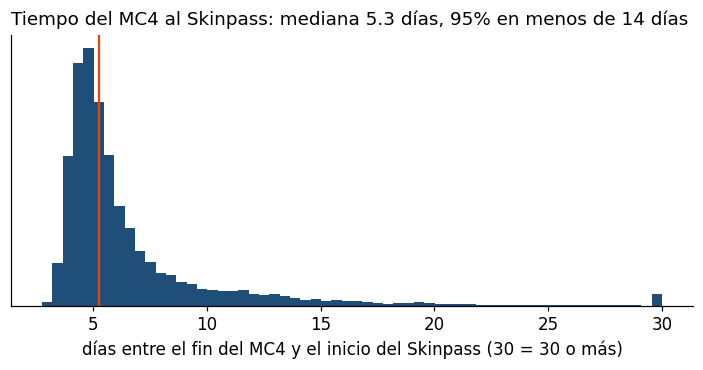

Espesor Entrada (SKP) = Espesor (MC4)        99.9
Ancho Entrada (SKP) = Ancho (MC4)           100.0
Ancho Salida (SKP) = Ancho Entrada (SKP)    100.0

Peso Entrada (SKP) = Peso (MC4) en rollos no divididos: 99.4%
Peso que se pierde en el Skinpass por rollo (mediana): 150 kg


In [21]:
L = skp.merge(
    mc4[['Material Salida', 'Fecha Fin', 'Espesor', 'Ancho', 'Peso']].rename(
        columns={'Material Salida': 'Material Entrada', 'Fecha Fin': 'Fin MC4', 'Espesor': 'Espesor MC4',
                 'Ancho': 'Ancho MC4', 'Peso': 'Peso MC4'}),
    on='Material Entrada')
dias = (L['Fecha Inicio'] - L['Fin MC4']).dt.total_seconds() / 86400

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(dias.clip(upper=30), bins=60, color=COLORES['azul'])
ax.axvline(dias.median(), color=COLORES['naranja'], lw=1.5)
ax.set_xlabel('días entre el fin del MC4 y el inicio del Skinpass (30 = 30 o más)'); ax.set_yticks([])
ax.set_title(f'Tiempo del MC4 al Skinpass: mediana {dias.median():.1f} días, 95% en menos de {dias.quantile(.95):.0f} días')
guardar(fig, 'eda_mc4_a_skp_dias')
plt.show()

copias = pd.Series({
    'Espesor Entrada (SKP) = Espesor (MC4)': (L['Espesor Entrada'] - L['Espesor MC4']).abs().lt(0.001).mean(),
    'Ancho Entrada (SKP) = Ancho (MC4)': (L['Ancho Entrada'] - L['Ancho MC4']).abs().lt(0.01).mean(),
    'Ancho Salida (SKP) = Ancho Entrada (SKP)': (skp['Ancho Salida'] - skp['Ancho Entrada']).abs().lt(0.01).mean(),
}, name='% de piezas').mul(100).round(1)
print(copias.to_string())

entero = L[~L['Material Entrada'].duplicated(keep=False)]
perdida = L.groupby('Material Entrada').agg(salida=('Peso', 'sum'), entrada=('Peso Entrada', 'first'))
print(f"\nPeso Entrada (SKP) = Peso (MC4) en rollos no divididos: {(entero['Peso Entrada'] == entero['Peso MC4']).mean():.1%}")
print(f"Peso que se pierde en el Skinpass por rollo (mediana): {(perdida.entrada - perdida.salida).median():,.0f} kg")

**Qué vemos.**
- Un rollo tarda en mediana **5.3 días** en llegar al Skinpass, y casi todos llegan en menos de dos semanas. Un defecto que nace en el MC4 se descubre días después.
- **El Skinpass no vuelve a medir la entrada:** `Espesor Entrada`, `Ancho Entrada` y `Peso Entrada` son copias del MC4. Tampoco mide el ancho de salida: `Ancho Salida` es igual a `Ancho Entrada`. Por eso un defecto de ancho en el Skinpass es el ancho del MC4 comparado contra la tolerancia de la orden del Skinpass.
- Cada rollo pierde unos 150 kg en el Skinpass (despuntes y recortes). Con eso, más la división en piezas, cambia el peso que se compara contra la orden.

## Resumen
- **Datos completos y continuos:** 149,734 rollos del MC4 y 58,786 piezas del Skinpass en 2025.
- **Columnas:** casi la mitad son el bloque de 5 defectos. Hay 18 columnas vacías y 13 constantes en el MC4, y 10 y 5 en el Skinpass. No hay mediciones de punta ni de cola.
- **MC4:** espesor y ancho cumplen su tolerancia en más del 99% con el valor resumen; las temperaturas son lo que más se desvía. La mitad de los rollos sale RETENIDO, pero eso es retención para revisión, no rechazo.
- **Skinpass:** estira 1.5% en mediana; 91% en modo elongación. Las tensiones siguen al preset; la fuerza y el bending se corrigen sobre la marcha. El peso es la tolerancia que más se incumple (95.5%).
- **Entre líneas:** un rollo tarda 5.3 días en mediana en llegar al Skinpass, y el Skinpass no vuelve a medir espesor, ancho ni peso de entrada: los copia del MC4.
- **Reglas de limpieza fijas:** destino por ruta teórica, corona válida 0-300 µm, producto = norma | grado | rango de espesor.
- **Liga:** 97% de las piezas del Skinpass se ligan con su rollo de MC4, lo que permite estudiar entrada contra respuesta del Skinpass.